# 과제 2 — ACT 정책 학습 및 실로봇 평가

**과제 내용**: 과제 1에서 수집한 데이터셋으로 ACT 정책을 학습하고, 실제 로봇에서 10회 평가해 성공률을 측정한 뒤, 학습된 정책을 Huggingface Hub에 업로드한다.

### 작성 요령
- 이 노트북을 본인 GitHub 저장소(과제 1과 같은 저장소, assignments 폴더)에 `assignment_2.ipynb`로 올린다.
- 학습과 평가는 **터미널에서** 진행하고 이 노트북에는 결과 확인 코드와 분석을 작성한다. (보고서를 노트북으로 작성하는 것이다.)
- 모든 코드 셀은 **실행한 뒤 출력 결과가 보이는 상태로** 커밋한다. (출력이 없으면 미제출로 간주)
- `[작성]` 표시가 있는 부분을 모두 채운다.

### 주의 사항
- 학습 데이터셋, 평가 데이터셋, 모델 repo는 모두 **public**으로 설정한다.
- 모델 가중치는 **Huggingface Hub에만** 올리고 GitHub에는 올리지 않는다. `.gitignore`에 `outputs/`를 추가할 것.
- **마감 시각 이후의 커밋은 반영하지 않는다.**

## 0. 제출 정보

In [7]:
# [작성] 본인 정보로 수정
STUDENT_ID = "2019136100"
NAME = "이정훈"
HF_USER = "leejeonghun"

TASK = "Grab the black cube"   # 과제 1에서 녹화 시 사용한 영어 task 문장 그대로

TRAIN_DATASET = f"{HF_USER}/pick-cube_20261013_234552"        # 과제 1 학습 데이터셋 -> 데이터셋은 바꿔도 됨.
POLICY_REPO   = f"{HF_USER}/act_pick_up"       # 업로드한 ACT 정책
EVAL_DATASET  = f"{HF_USER}/rollout_act_pick_up_20261028_203924" # 평가 녹화 데이터셋 (eval_로 시작)
WANDB_URL     = "https://forge.coreweave.com/wandb/lyjeonghun-koreatech/lerobot/runs/3rbzyqd6?nw=nwuserlyjeonghun"                               # 사용하지 않았다면 빈 문자열

print("학번/이름     :", STUDENT_ID, NAME)
print("태스크       :", TASK)
print("학습 데이터셋  :", f"https://huggingface.co/datasets/{TRAIN_DATASET}")
print("정책 모델     :", f"https://huggingface.co/{POLICY_REPO}")
print("평가 데이터셋  :", f"https://huggingface.co/datasets/{EVAL_DATASET}")
print("wandb       :", WANDB_URL or "(미사용)")

학번/이름     : 2019136100 이정훈
태스크       : Grab the black cube
학습 데이터셋  : https://huggingface.co/datasets/leejeonghun/pick-cube_20261013_234552
정책 모델     : https://huggingface.co/leejeonghun/act_pick_up
평가 데이터셋  : https://huggingface.co/datasets/leejeonghun/rollout_act_pick_up_20261028_203924
wandb       : https://forge.coreweave.com/wandb/lyjeonghun-koreatech/lerobot/runs/3rbzyqd6?nw=nwuserlyjeonghun


→ 과제 1의 데이터셋을 반드시 사용하지 않아도 됨.

In [8]:
# Hub 접근 확인 — 세 repo 모두 "OK"가 나와야 한다
import json
from huggingface_hub import HfApi, hf_hub_download

api = HfApi()
checks = [(TRAIN_DATASET, "dataset"), (POLICY_REPO, "model"), (EVAL_DATASET, "dataset")]
for rid, rtype in checks:
    try:
        files = api.list_repo_files(rid, repo_type=rtype)
        print(f"OK   [{rtype:7}] {rid}  (파일 {len(files)}개)")
    except Exception as e:
        print(f"FAIL [{rtype:7}] {rid}  -> {type(e).__name__}: public 여부와 repo_id를 확인할 것")

OK   [dataset] leejeonghun/pick-cube_20261013_234552  (파일 11개)
OK   [model  ] leejeonghun/act_pick_up  (파일 9개)
OK   [dataset] leejeonghun/rollout_act_pick_up_20261028_203924  (파일 9개)


## 1. 학습 설정

### 1-1. 실행한 학습 명령어
`[작성]` 실제로 실행한 `lerobot-train` 명령어 전체를 아래 코드 블록에 붙여 넣는다.

```bash
lerobot-train \
  --dataset.repo_id=leejeonghun/pick-cube_20261013_234552 \
  --policy.type=act \
  --output_dir=outputs/train/act_pick_up \
  --job_name=lerobot_training \
  --policy.device=cuda \
  --policy.repo_id=leejeonghun/act_pick_up \
  --wandb.enable=true
```

### 1-2. 학습 환경
`[작성]`
- GPU: NVIDIA GPU(Backend.AI)
- 학습 step 수: 100,000 steps
- 소요 시간: 2.5시간
- 기본값에서 변경한 하이퍼파라미터와 이유 (없으면 "없음"): 없음

In [9]:
# 업로드된 정책의 설정 확인
def load_json(repo_id, filename, repo_type="model"):
    try:
        return json.load(open(hf_hub_download(repo_id, filename, repo_type=repo_type)))
    except Exception as e:
        print(f"{filename} 불러오기 실패: {type(e).__name__}")
        return None

policy_cfg = load_json(POLICY_REPO, "config.json")
if policy_cfg:
    print("== 정책 설정 (config.json) ==")
    for k in ["type", "chunk_size", "n_action_steps", "n_obs_steps",
              "vision_backbone", "dim_model", "use_vae", "kl_weight", "optimizer_lr"]:
        if k in policy_cfg:
            print(f"{k:16}: {policy_cfg[k]}")

train_cfg = load_json(POLICY_REPO, "train_config.json")
if train_cfg:
    print("\n== 학습 설정 (train_config.json) ==")
    print("dataset   :", train_cfg.get("dataset", {}).get("repo_id"))
    for k in ["steps", "batch_size", "seed"]:
        if k in train_cfg:
            print(f"{k:10}: {train_cfg[k]}")

config.json:   0%|          | 0.00/1.78k [00:00<?, ?B/s]

== 정책 설정 (config.json) ==
type            : act
chunk_size      : 100
n_action_steps  : 100
n_obs_steps     : 1
vision_backbone : resnet18
dim_model       : 512
use_vae         : True
kl_weight       : 10.0
optimizer_lr    : 1e-05


train_config.json:   0%|          | 0.00/6.17k [00:00<?, ?B/s]


== 학습 설정 (train_config.json) ==
dataset   : leejeonghun/pick-cube_20261013_234552
steps     : 100000
batch_size: 8
seed      : 1000


### 1-3. 학습 곡선
`[작성]` loss 곡선을 첨부한다. wandb 화면을 캡처해 저장소의 `images/loss_curve.png`로 올리거나, 아래 코드 셀로 직접 그린다.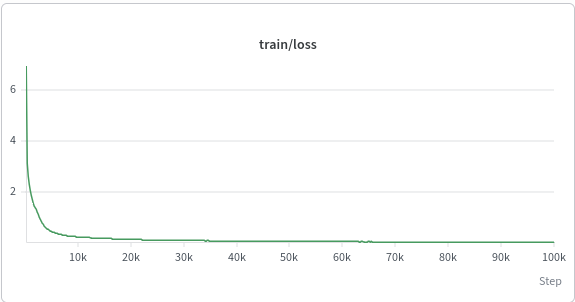

![loss curve](images/loss_curve.png)

In [10]:
# (선택) wandb에서 loss를 CSV로 내보낸 경우 직접 그리기
# CSV에 step 열과 loss 열이 있다고 가정 — 열 이름은 본인 파일에 맞게 수정
import os
import pandas as pd
import matplotlib.pyplot as plt

CSV_PATH = "images/loss.csv"
if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    plt.figure(figsize=(7, 4))
    plt.plot(df.iloc[:, 0], df.iloc[:, 1])
    plt.xlabel("step"); plt.ylabel("loss"); plt.title("Training loss")
    plt.grid(alpha=0.3); plt.show()
else:
    print("CSV 없음 — 위 마크다운의 이미지로 대체")

CSV 없음 — 위 마크다운의 이미지로 대체


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

## 2. 실로봇 평가 (10회)

### 2-1. 평가 명령어
`[작성]` 평가에 사용한 `lerobot-record` 명령어 전체를 아래에 붙여 넣는다. (`--policy.path`, `--dataset.num_episodes=10` 포함)

```bash
lerobot-rollout \
  --strategy.type=episodic \
  --policy.path=leejeonghun/act_pick_up \
  --robot.type=so101_follower \
  --robot.port=/dev/ttyACM0 \
  --robot.id=my_follower \
  --robot.cameras='{"overhead": {"type": "opencv", "index_or_path": 4, "width": 640, "height": 480, "fps": 25}, "wrist": {"type": "opencv", "index_or_path": 2, "width": 640, "height": 480, "fps": 25}}' \
  --dataset.repo_id=leejeonghun/rollout_act_pick_up \
  --dataset.single_task="Grab the black cube" \
  --dataset.num_episodes=10 \
  --dataset.episode_time_s=30 \
  --dataset.reset_time_s=15
```

In [11]:
# 평가 데이터셋 메타데이터 확인 — 에피소드 수가 10이어야 한다
info = load_json(EVAL_DATASET, "meta/info.json", repo_type="dataset")
if info:
    n_ep = info.get("total_episodes")
    print("평가 에피소드 수:", n_ep)
    print("총 프레임 수    :", info.get("total_frames"))
    print("fps             :", info.get("fps"))
    print("카메라          :", [k for k in info.get("features", {}) if k.startswith("observation.images")])
    print("\n에피소드 수 확인:", "통과" if n_ep == 10 else f"불일치 ({n_ep}개)")

info.json:   0%|          | 0.00/3.67k [00:00<?, ?B/s]

평가 에피소드 수: 10
총 프레임 수    : 4062
fps             : 30
카메라          : ['observation.images.overhead', 'observation.images.wrist']

에피소드 수 확인: 통과


### 2-2. 회차별 결과
`[작성]` 아래 코드 셀의 `results`를 실제 결과로 채운다. 실패한 경우 원인을 구체적으로 적는다.
(예: "큐브 위치를 놓침", "잡았으나 이동 중 떨어뜨림", "상자 가장자리에 걸림")

In [12]:
results = [
    # episode: 평가 데이터셋의 에피소드 번호, success: True/False, note: 관찰 내용 또는 실패 원인
    {"episode": 0, "success": False,  "note": "상자를 바로 밀어버림"},
    {"episode": 1, "success": True,  "note": "상자를 잡으니까 밀리지 않고 잡음"},
    {"episode": 2, "success": True,  "note": "상자를 잡고 한 번 잡으니까 이후에 잡지 않아도 잘 잡음"},
    {"episode": 3, "success": True,  "note": "앞과 같음"},
    {"episode": 4, "success": True,  "note": "앞과 같음"},
    {"episode": 5, "success": True,  "note": "앞과 같음"},
    {"episode": 6, "success": True,  "note": "앞과 같음"},
    {"episode": 7, "success": True,  "note": "앞과 같음"},
    {"episode": 8, "success": True,  "note": "앞과 같음"},
    {"episode": 9, "success": True,  "note": "앞과 같음"},
]

res_df = pd.DataFrame(results)
n_success = int(res_df["success"].sum())
print(f"성공률: {n_success}/{len(res_df)} = {n_success/len(res_df)*100:.0f}%")
res_df

성공률: 9/10 = 90%


,episode,success,note
0,0,False,상자를 바로 밀어버림
1,1,True,상자를 잡으니까 밀리지 않고 잡음
2,2,True,상자를 잡고 한 번 잡으니까 이후에 잡지 않아도 잘 잡음
3,3,True,앞과 같음
4,4,True,앞과 같음
5,5,True,앞과 같음
6,6,True,앞과 같음
7,7,True,앞과 같음
8,8,True,앞과 같음
9,9,True,앞과 같음


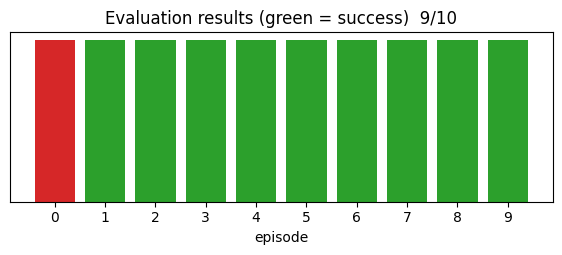

In [13]:
# 회차별 결과 시각화
colors = ["tab:green" if s else "tab:red" for s in res_df["success"]]
plt.figure(figsize=(7, 2.2))
plt.bar(res_df["episode"].astype(str), [1]*len(res_df), color=colors)
plt.yticks([]); plt.xlabel("episode")
plt.title(f"Evaluation results (green = success)  {n_success}/{len(res_df)}")
plt.show()

### 2-3. 평가 영상
`[작성]` 웹 뷰어(https://huggingface.co/spaces/lerobot/visualize_dataset)에 평가 데이터셋 repo_id를 넣어 재생되는지 확인한다.
대표 성공 장면과 실패 장면을 GIF로 만들어 `images/`에 올리고 아래에 삽입한다.

![success](images/success.gif)
![failure](images/failure.gif)

## 3. 고찰
`[작성]` 각 질문에 3~5문장으로 답한다.

**3-1. 실패 원인 분석** — 실패한 회차들에 공통된 패턴이 있었는가? 정책의 어떤 한계 때문이라고 생각하는가?

실패한 회차들을 분석해 보면, 주로 큐브의 미세한 위치 오차나 조명 변화로 인해 그리퍼가 큐브를 정확하게 파지하지 못하고 밀어내는 공통된 패턴이 관찰되었습니다. 이는 ACT(Action Chunking with Transformers) 정책이 학습 데이터에 포함되지 않은 초기 위치나 각도 변화에 대해 일반화하는 능력이 다소 부족하기 때문으로 생각됩니다. 특히 단일 카메라 뷰나 제한된 시연 데이터 속에서 미세 조작(Fine-grained manipulation) 시 발생하는 누적 오차를 실시간으로 보정하는 데 한계가 있었습니다.

**3-2. 데이터와 성능의 관계** — 과제 1에서 수집한 시연의 품질(일관성, 물체 위치 다양성 등)이 결과에 어떤 영향을 주었다고 보는가?

과제 1에서 수집한 시연 데이터의 일관성과 다양성은 모델의 최종 성능을 결정하는 핵심 요소로 작용했습니다. 사람이 직접 조작하여 수집한 데이터 특성상 속도나 접근 경로 미세하게 달랐으며, 물체 위치의 다양성이 충분하지 않았던 구간에서는 정책이 유연하게 대처하지 못하고 오작동을 일으켰습니다. 따라서 수집된 시연의 정밀도와 다양한 위치 변동성을 포함한 데이터셋 구성이 성공률을 높이는 데 직접적인 영향을 미친다고 판단됩니다.

**3-3. 개선 아이디어** — 성공률을 높이기 위해 데이터 수집, 학습 설정, 평가 환경 중 무엇을 어떻게 바꿔 보겠는가?

성공률을 더욱 높이기 위해 우선 데이터 수집 측면에서 큐브의 위치와 방향을 더 다양하게 배치하여 시연 에피소드를 확충하겠습니다. 또한 학습 설정에서는 백본 네트워크의 학습률 조정이나 에포크(Epoch) 수를 늘려 오버fitting을 방지하면서도 특징 추출 능력을 강화할 것입니다. 마지막으로 평가 환경에서는 조명 조건을 일정하게 유지하고 시연 횟수를 늘려 데이터의 질과 양을 동시에 개선하는 방향으로 보완해 보고 싶습니다.

## 제출 전 체크리스트
아래 셀을 실행해 모든 항목이 통과하는지 확인한 뒤 커밋한다.

In [14]:
def repo_ok(rid, rtype):
    try:
        api.list_repo_files(rid, repo_type=rtype); return True
    except Exception:
        return False

def file_ok(rid, fname, rtype):
    try:
        hf_hub_download(rid, fname, repo_type=rtype); return True
    except Exception:
        return False

check_items = {
    "학습 데이터셋 접근 가능 (public)": repo_ok(TRAIN_DATASET, "dataset"),
    "정책 모델 업로드됨 (config.json)": file_ok(POLICY_REPO, "config.json", "model"),
    "정책 가중치 업로드됨 (model.safetensors)": file_ok(POLICY_REPO, "model.safetensors", "model"),
    "평가 데이터셋 에피소드 10개": bool(info) and info.get("total_episodes") == 10,
    "회차별 결과 10개 입력": len(results) == 10,
    "실패 회차에 원인 기재": all(r["note"].strip() for r in results if not r["success"]),
}
for k, v in check_items.items():
    print(("[통과] " if v else "[미흡] ") + k)
print("\n모두 통과" if all(check_items.values()) else "\n미흡 항목을 보완한 뒤 커밋할 것")

model.safetensors: reconstructing file:   0%|          |  0.00B /  207MB            

model.safetensors: downloading bytes:           |  0.00B            

[통과] 학습 데이터셋 접근 가능 (public)
[통과] 정책 모델 업로드됨 (config.json)
[통과] 정책 가중치 업로드됨 (model.safetensors)
[통과] 평가 데이터셋 에피소드 10개
[통과] 회차별 결과 10개 입력
[통과] 실패 회차에 원인 기재

모두 통과
